# RQ2 TIB validation cohort EDA — dataset characterization

**Historical 20-item Lecture diagnostic.** The current EDA for all pinned `train`, `valid`, and `test` records is `rq2-tib-all-splits-eda-colab.ipynb`; do not treat the outputs below as all-dataset evidence.

This notebook describes **creator `gigant/tib`**, pinned revision `e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee`. Statistical unit: one talk. It reads the **`valid` split only** and projects `doi/title/author` from `train` for leakage screening. It never reads `test` content.

Selection: exact `Lecture` genre, DOI, source URL, nonempty timed transcript, then SHA-256 DOI ordering and one exact author per selected record. The selected 20 are a **development diagnostic cohort**, not an official final H2 cohort. Dataset creator says transcripts are automatic ASR; abstract is source archive metadata with variable style, not verified summary ground truth. [Creator card](https://huggingface.co/datasets/gigant/tib/blob/main/README.md).
The first code cell finds the repository root and runs from there, so the notebook also works when Jupyter starts in this notebook directory. The full dataset scan still requires access to the pinned Hugging Face revision.

Saved results are from the pinned validation scan. The structural-exclusion cell has executed and shows the exact adjacent segment starts that caused the one-record exclusion.


In [1]:
from pathlib import Path
import os
import runpy
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "experiments/scripts/rq2-tib-valid-eda.py").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the multimodal-lecture-summarizer repository")
os.chdir(REPO_ROOT)  # Later cells use repository-relative paths.
module = runpy.run_path(str(REPO_ROOT / "experiments/scripts/rq2-tib-valid-eda.py"))
rows = module["scan_validation"]()
selected = module["select_diagnostic"](rows)
receipt = module["write_receipt"](rows, selected, Path("plans/261002-0946-rq2-controlled-summarization/rq2-tib-valid-diagnostic-receipt.json"))
df = pd.DataFrame(rows)
cohort = pd.DataFrame(selected)
print("TIB revision:", receipt["revision"], "split:", receipt["split_read"])
print("Validation records:", len(df), "Lecture records:", receipt["lecture_count"], "preliminary candidates:", receipt["candidate_count"], "selected:", len(cohort))
print("Selected DOI digest:", receipt["selected_doi_sha256"])

TIB revision: e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee split: valid
Validation records: 910 Lecture records: 71 preliminary candidates: 70 selected: 20
Selected DOI digest: 690512dcbc220b9a7da3f2ec72448abc685e9c3fd9f4c1a40f8ae4ebee085759


In [2]:
print("GENRE (top 12)")
print(df.genre.value_counts(dropna=False).head(12).to_string())
lecture = df[df.genre.str.casefold() == "lecture"]
mixed_lecture = df[df.genre.str.casefold().str.contains("lecture") & df.genre.str.casefold().ne("lecture")]
print("\nExact Lecture:", len(lecture), "mixed Lecture tags:", len(mixed_lecture))
print("\nLECTURE FIELD CHECKS")
for key in ["doi", "author", "source_url_present", "video_url_present", "segments_aligned", "segments_valid_times", "segments_ordered"]:
    missing = lecture[key].eq("").sum() if key in ("doi", "author") else (~lecture[key]).sum()
    print(f"{key}: {int(missing)}/{len(lecture)} absent or invalid")
print("DOI/source URL mismatches:", int(lecture.doi_source_url_match.eq(False).sum()), "unparseable:", int(lecture.doi_source_url_match.isna().sum()))
print("Duplicate DOI in validation:", int(df.doi[df.doi.ne("")].duplicated().sum()))
print("Duplicate exact title in validation:", int(df.title.str.casefold().str.strip().replace("", pd.NA).dropna().duplicated().sum()))
print("Duplicate author in selected:", int(cohort.author[cohort.author.ne("")].duplicated().sum()))
# Show every excluded exact-Lecture row and the first adjacent timestamp inversion.
structural_ok = (
    lecture.doi.ne("") & lecture.source_url_present & lecture.transcript_words.gt(0)
    & lecture.segment_count.ge(2) & lecture.segments_valid_times & lecture.segments_ordered
)
excluded = lecture.loc[~structural_ok]
exclusion_rows = []
for _, row in excluded.iterrows():
    reasons = []
    if not row.doi: reasons.append("DOI missing")
    if not row.source_url_present: reasons.append("source URL missing")
    if row.transcript_words <= 0: reasons.append("transcript empty")
    if row.segment_count < 2: reasons.append("fewer than 2 segments")
    if not row.segments_valid_times: reasons.append("invalid segment times")
    if not row.segments_ordered: reasons.append("segment starts out of order")
    inversion = row.first_start_inversion or {}
    exclusion_rows.append({
        "DOI": row.doi,
        "Reason": ", ".join(reasons),
        "Previous segment (0-based)": inversion.get("previous_segment"),
        "Previous start (s)": inversion.get("previous_start_seconds"),
        "Next segment (0-based)": inversion.get("current_segment"),
        "Next start (s)": inversion.get("current_start_seconds"),
    })
print(f"Structural eligibility: {len(lecture)} exact Lecture -> {int(structural_ok.sum())} eligible; {len(excluded)} excluded")
display(pd.DataFrame(exclusion_rows))
assert int(structural_ok.sum()) == receipt["candidate_count"]

GENRE (top 12)
genre
Conference/Talk                                          810
Lecture                                                   71
Workshop/Interactive Format\nLecture                      11
Webinar/Tutorial                                          10
Lecture\nConference/Talk                                   3
Conference/Talk\nLecture                                   2
Conference/Talk\nWorkshop/Interactive Format               2
Conference/Talk\nLecture\nWorkshop/Interactive Format      1

Exact Lecture: 71 mixed Lecture tags: 17

LECTURE FIELD CHECKS
doi: 0/71 absent or invalid
author: 0/71 absent or invalid
source_url_present: 0/71 absent or invalid
video_url_present: 0/71 absent or invalid
segments_aligned: 0/71 absent or invalid
segments_valid_times: 0/71 absent or invalid
segments_ordered: 1/71 absent or invalid
DOI/source URL mismatches: 0 unparseable: 1
Duplicate DOI in validation: 0
Duplicate exact title in validation: 1
Duplicate author in selected: 0
Structural

,DOI,Reason,Previous segment (0-based),Previous start (s),Next segment (0-based),Next start (s)
0,10.5446/20230 (DOI),segment starts out of order,220,2585.0,221,1607.97998


### Structural exclusion decision

| Exact Lecture records | Structurally eligible | Excluded DOI | Recorded failure |
|---:|---:|---|---|
| 71 | 70 | `10.5446/20230 (DOI)` | `segments_ordered = false`: at least one later segment starts before its preceding segment. |

The table above is supported by the pinned diagnostic receipt. The executed code cell above shows the first offending pair: segment 220 starts at 2585.0 s, then segment 221 starts at 1607.97998 s (about 16 min 17 s earlier). This rule protects timed-transcript comparisons; it does not assess lecture content or abstract quality. Selection of 20 diagnostic talks is a later SHA-256/author step among the 70 eligible talks. The other anomaly, `10.14288/1.0398145`, has a DOI outside the numeric TIB DOI namespace and is **not** excluded for that reason.


In [3]:
print("SELECTED COHORT DISTRIBUTIONS")
print(cohort[["transcript_words", "abstract_words", "segment_count", "duration_minutes", "segment_word_ratio", "segment_overlaps", "empty_segment_texts"]].describe(percentiles=[.1,.25,.5,.75,.9]).round(2).to_string())
print("\nSUBJECTS")
print(cohort.subject.value_counts(dropna=False).head(10).to_string())
print("\nLANGUAGES")
print(cohort.language.value_counts(dropna=False).to_string())
print("\nABSTRACTS UNDER 30 WORDS:", int((cohort.abstract_words < 30).sum()))
print("DOI/source URL mismatches:", int(cohort.doi_source_url_match.eq(False).sum()), "unparseable:", int(cohort.doi_source_url_match.isna().sum()))
print("Unordered segments:", int((~cohort.segments_ordered).sum()))
print("\nSELECTED DOI")
print(cohort[["doi", "author", "transcript_words", "segment_count", "duration_minutes", "segment_word_ratio", "segment_overlaps", "abstract_words"]].round(2).to_string(index=False))

SELECTED COHORT DISTRIBUTIONS
       transcript_words  abstract_words  segment_count  duration_minutes  segment_word_ratio  segment_overlaps  empty_segment_texts
count             20.00           20.00          20.00             20.00                20.0              20.0                 20.0
mean            6850.55           56.10         612.05             51.80                 1.0               0.0                  0.0
std             3541.99           44.71         409.39             26.11                 0.0               0.0                  0.0
min              882.00            3.00          79.00              6.64                 1.0               0.0                  0.0
10%             2019.10           12.80         133.70             14.68                 1.0               0.0                  0.0
25%             3737.50           18.00         325.25             27.94                 1.0               0.0                  0.0
50%             7881.00           53.50       

In [4]:
import json
train_overlap = module["scan_train_metadata_overlap"](selected)
train_overlap_path = Path("plans/261002-0946-rq2-controlled-summarization/rq2-tib-valid-train-overlap.json")
train_overlap_path.write_text(json.dumps(train_overlap, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Train metadata rows scanned:", train_overlap["train_records_scanned"])
print("Train columns read:", train_overlap["columns_read"])
print("Selected DOI also in train:", train_overlap["selected_doi_in_train"])
print("Selected exact title also in train:", train_overlap["selected_exact_title_in_train"])
print("Selected authors with train records:", len(train_overlap["selected_author_train_record_counts"]))
print(train_overlap["selected_author_train_record_counts"])

Train metadata rows scanned: 7282
Train columns read: ['doi', 'title', 'author']
Selected DOI also in train: []
Selected exact title also in train: ['10.5446/49247 (DOI)']
Selected authors with train records: 13
{'10.5446/38638 (DOI)': 1, '10.5446/50934 (DOI)': 1, '10.5446/15101 (DOI)': 53, '10.5446/49452 (DOI)': 2, '10.5446/45978 (DOI)': 6, '10.5446/49247 (DOI)': 3, '10.5446/18890 (DOI)': 17, '10.5446/16294 (DOI)': 1, '10.5446/46066 (DOI)': 11, '10.5446/35254 (DOI)': 1, '10.5446/48908 (DOI)': 4, '10.5446/19217 (DOI)': 31, '10.5446/49509 (DOI)': 2}


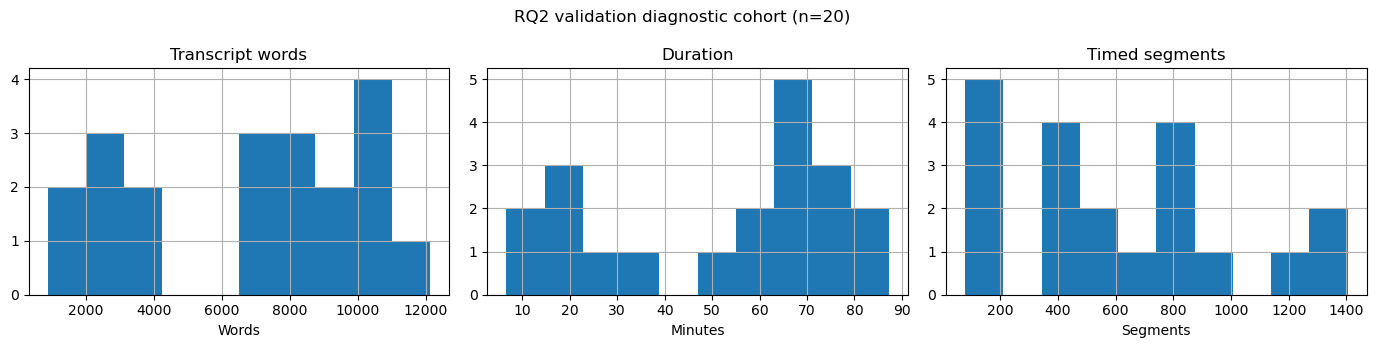

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
cohort.transcript_words.hist(ax=axes[0], bins=10)
axes[0].set(title="Transcript words", xlabel="Words")
cohort.duration_minutes.dropna().hist(ax=axes[1], bins=10)
axes[1].set(title="Duration", xlabel="Minutes")
cohort.segment_count.hist(ax=axes[2], bins=10)
axes[2].set(title="Timed segments", xlabel="Segments")
fig.suptitle("RQ2 validation diagnostic cohort (n=20)")
fig.tight_layout()
plt.show()

## What one record actually contains

Each row has DOI, archive/video URLs, author/title/subject/year/language, a text transcript and timed ASR segments, an abstract, license text, and keyframe **filenames plus frame/time ranges**. Keyframe metadata does **not** contain slide pixels or OCR. The table below inspects the same 20 selected DOI; raw video/audio is not downloaded. Short transcript examples are data excerpts, not transcript accuracy evidence.

In [6]:
from IPython.display import display
import json
detail_module = runpy.run_path("experiments/scripts/rq2_tib_valid_detail_eda.py")
details = detail_module["scan_selected_details"](selected)
assert [row["doi"] for row in details] == [row["doi"] for row in selected]
detail_path = Path("experiments/outputs/diagnostic/rq2_eda/selected_valid_details.json")
detail_path.parent.mkdir(parents=True, exist_ok=True)
detail_path.write_text(json.dumps({"dataset": receipt["dataset"], "revision": receipt["revision"], "split": "valid", "selection_sha256": receipt["selected_doi_sha256"], "test_content_accessed": False, "items": details}, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
detail_df = pd.DataFrame(details)
detail_df["doi_id"] = detail_df.doi.str.extract(r"/(\d+)")[0]
detail_df["train_author_rows"] = detail_df.doi.map(train_overlap["selected_author_train_record_counts"]).fillna(0).astype(int)
print("Selected source rows:", len(detail_df), "detail receipt:", detail_path)
print("Fields in a creator TIB row: DOI, title, URL, video URL, license, subject, genre, year, author, contributors, abstract, transcript, timed transcript_segments, keyframe metadata, language.")
display(detail_df[["doi_id", "subject", "duration_minutes", "transcript_words", "segment_count", "abstract_words", "keyframe_count", "train_author_rows", "license_label"]].rename(columns={"duration_minutes":"minutes", "transcript_words":"ASR words", "segment_count":"ASR segments", "abstract_words":"abstract words", "keyframe_count":"keyframe intervals", "train_author_rows":"same-author train rows"}))

Selected source rows: 20 detail receipt: experiments\outputs\diagnostic\rq2_eda\selected_valid_details.json
Fields in a creator TIB row: DOI, title, URL, video URL, license, subject, genre, year, author, contributors, abstract, transcript, timed transcript_segments, keyframe metadata, language.


,doi_id,subject,minutes,ASR words,ASR segments,abstract words,keyframe intervals,same-author train rows,license_label
0,45978,Chemistry,16.57,2046,168,74,9,6,CC Attribution 3.0 Germany:
1,50943,Mathematics\nPhysics,73.05,10829,462,95,120,0,CC Attribution 3.0 Unported:
2,46066,Architecture,71.93,12131,1404,105,75,11,CC Attribution - NonCommercial - ShareAlike 3....
3,49509,Linguistics,14.85,2384,113,19,18,2,CC Attribution - NonCommercial - NoDerivatives...
4,16294,Mathematics,70.47,10415,1375,15,75,1,CC Attribution 3.0 Unported:
5,48908,Linguistics,13.18,1777,136,22,14,4,CC Attribution - NonCommercial - NoDerivatives...
6,38319,Architecture,72.82,8593,580,89,68,0,CC Attribution 3.0 Unported:
7,20846,Computer Science\nMathematics,63.20,9369,944,81,68,0,CC Attribution 3.0 Unported:
8,38638,Chemistry,34.25,4102,404,3,41,1,CC Attribution 3.0 Unported:
9,14078,Physics,61.60,6637,847,68,40,0,CC Attribution - NonCommercial - ShareAlike 3....


In [7]:
availability = pd.DataFrame([
    {"field / evidence": "DOI and source landing URL", "records": int(detail_df.source_url.ne("").sum()), "meaning": "Stable source link; landing page is not media access"},
    {"field / evidence": "Timed ASR transcript", "records": int(detail_df.segment_count.gt(0).sum()), "meaning": "Text generated by ASR; speech accuracy unmeasured"},
    {"field / evidence": "Archive abstract", "records": int(detail_df.abstract_words.gt(0).sum()), "meaning": "Metadata with variable quality; 0 formally qualified references"},
    {"field / evidence": "Video URL field", "records": int(detail_df.video_url_present.sum()), "meaning": "URL present; video bytes not downloaded"},
    {"field / evidence": "Keyframe names and time ranges", "records": int(detail_df.keyframe_count.gt(0).sum()), "meaning": "Index metadata only; no slide pixels/OCR"},
    {"field / evidence": "Downloaded/validated slide pixels + OCR", "records": 0, "meaning": "S4 input not materialized for this cohort"},
    {"field / evidence": "Audio sampled against ASR", "records": int(detail_df.audio_sample_read.sum()), "meaning": "WER or transcript accuracy unavailable"},
])
display(availability)
example = detail_df.iloc[0]
print("Example keyframe metadata:", example.doi_id, example.first_keyframe_filename, example.first_keyframe_seconds, "seconds; no image pixels in this row")

,field / evidence,records,meaning
0,DOI and source landing URL,20,Stable source link; landing page is not media ...
1,Timed ASR transcript,20,Text generated by ASR; speech accuracy unmeasured
2,Archive abstract,20,Metadata with variable quality; 0 formally qua...
3,Video URL field,20,URL present; video bytes not downloaded
4,Keyframe names and time ranges,20,Index metadata only; no slide pixels/OCR
5,Downloaded/validated slide pixels + OCR,0,S4 input not materialized for this cohort
6,Audio sampled against ASR,0,WER or transcript accuracy unavailable


Example keyframe metadata: 45978 PCB4_0_251.png [0.0, 10.08] seconds; no image pixels in this row


In [8]:
print("SELECTED-COHORT QUALITY AND MODALITY CHECKS")
print("Transcript/segment normalized token sequence agrees:", int(detail_df.transcript_matches_segments.sum()), "/", len(detail_df))
print("Whitespace word counts agree:", int(detail_df.whitespace_word_count_matches.sum()), "/", len(detail_df), "; one punctuation-spacing difference in DOI 43747")
print("Zero-duration ASR segments:", int(detail_df.zero_duration_segments.sum()), "across", int((detail_df.zero_duration_segments > 0).sum()), "talks")
print("Gaps over 30 seconds:", int(detail_df.gaps_over_30_sec.sum()))
print("Keyframe arrays aligned:", int(detail_df.keyframe_arrays_aligned.sum()), "/", len(detail_df))
print("Keyframe intervals ordered:", int(detail_df.keyframe_intervals_ordered.sum()), "/", len(detail_df))
print("Keyframe metadata count:", int(detail_df.keyframe_count.sum()), "(pixels read: 0; OCR read: 0)")
print("Keyframe/transcript end drift >5 seconds:", int((detail_df.keyframe_last_minus_transcript_end_sec.abs() > 5).sum()))
print("Audio samples read:", int(detail_df.audio_sample_read.sum()), "; ASR WER: not measured")
print("Source video URLs present:", int(detail_df.video_url_present.sum()), "/", len(detail_df), "(media access not tested here)")
print("\nLicense first-line labels:")
print(detail_df.license_label.value_counts().to_string())
print("\nSubject categories:")
print(detail_df.subject.value_counts().to_string())

SELECTED-COHORT QUALITY AND MODALITY CHECKS
Transcript/segment normalized token sequence agrees: 20 / 20
Whitespace word counts agree: 19 / 20 ; one punctuation-spacing difference in DOI 43747
Zero-duration ASR segments: 1 across 1 talks
Gaps over 30 seconds: 0
Keyframe arrays aligned: 20 / 20
Keyframe intervals ordered: 20 / 20
Keyframe metadata count: 1012 (pixels read: 0; OCR read: 0)
Keyframe/transcript end drift >5 seconds: 8
Audio samples read: 0 ; ASR WER: not measured
Source video URLs present: 20 / 20 (media access not tested here)

License first-line labels:
license_label
CC Attribution 3.0 Unported:                                         8
CC Attribution - NonCommercial - NoDerivatives 3.0 Germany:          4
CC Attribution 3.0 Germany:                                          2
CC Attribution - NonCommercial - ShareAlike 3.0 Unported:            1
CC Attribution - NonCommercial - ShareAlike 3.0 USA:                 1
CC Attribution - NonCommercial - NoDerivatives 4.0 Inter

## What the abstracts look like

The dataset abstract is archive metadata. Presence and length do not show that it covers the individual talk or that every claim is supported by the speech. The examples below are chosen mechanically by abstract word count (shortest, median, longest) plus a course-level counterexample. The [per-record reference screen](../../../plans/261002-0946-rq2-controlled-summarization/rq2-tib-valid-reference-screen.json) records a conservative analyst screen, **not ground-truth labels**. No author identity is inferred from the creator's “likely author-provided” wording.

In [9]:
screen = json.loads(Path("plans/261002-0946-rq2-controlled-summarization/rq2-tib-valid-reference-screen.json").read_text(encoding="utf-8"))
assert screen["revision"] == receipt["revision"] and screen["split"] == "valid"
assert set(screen["items"]) == set(detail_df.doi_id)
detail_df["reference_screen"] = detail_df.doi_id.map(lambda value: screen["items"][value]["screen"])
detail_df["screen_reason"] = detail_df.doi_id.map(lambda value: screen["items"][value]["reason"])
detail_df["archive_relation"] = detail_df.doi_id.map(lambda value: screen["items"][value]["archive_match"])
print("Archive abstract relation:", detail_df.archive_relation.value_counts().to_dict())
print("Reference screen:", detail_df.reference_screen.value_counts().to_dict(), "; formally qualified: 0")
display(detail_df[["doi_id", "abstract_words", "abstract_preview", "archive_relation", "reference_screen", "screen_reason"]])
ordered = detail_df.sort_values(["abstract_words", "doi_id"])
sample_ids = list(dict.fromkeys([ordered.iloc[0].doi_id, ordered.iloc[len(ordered)//2].doi_id, ordered.iloc[-1].doi_id, "50943"]))
for doi_id in sample_ids:
    row = detail_df[detail_df.doi_id == doi_id].iloc[0]
    print("\nDOI", doi_id, "|", row.title, "|", row.abstract_words, "abstract words |", row.reference_screen)
    print("ABSTRACT:", row.abstract_text)
    print("MID-TRANSCRIPT ASR EXCERPT:", row.transcript_example)
    print("SOURCE:", row.source_url)

Archive abstract relation: {'exact_normalized': 16, 'cleaned_substring': 3, 'editorial_variant': 1}
Reference screen: {'candidate_unverified': 12, 'unsuitable': 8} ; formally qualified: 0


,doi_id,abstract_words,abstract_preview,archive_relation,reference_screen,screen_reason
0,45978,74,PhysChemBasics#4: Affinity 101 The 1st and 2nd...,exact_normalized,candidate_unverified,Talk-specific abstract; source support not ver...
1,50943,95,Algebraic K-theory is an invariant of rings an...,exact_normalized,unsuitable,Mini-course description for part 3 of 3
2,46066,105,Roman Architecture (HSAR 252) Professor Kleine...,editorial_variant,candidate_unverified,Narrative abstract differs in punctuation; arc...
3,49509,19,Introduction to the nominal morphology of Goth...,exact_normalized,candidate_unverified,Gothic morphology outline; source support unve...
4,16294,15,Topics: Short overview. The category of stable...,exact_normalized,candidate_unverified,Brief topic outline; coverage uncertain
5,48908,22,This lecture focuses on various selected topic...,exact_normalized,candidate_unverified,Phonology topics; source support unverified
6,38319,89,Oliver Thill (1971) is an architect from Karl-...,exact_normalized,unsuitable,Speaker biography and event metadata dominate
7,20846,81,Renegar's condition number is a data-driven co...,exact_normalized,candidate_unverified,Talk-specific abstract; source support not ver...
8,38638,3,Chromatographic separation; Chapters:,cleaned_substring,unsuitable,Three-word chapter stub
9,14078,68,"On May 16, 2011, Professor of Physics Emeritus...",exact_normalized,unsuitable,Book-signing event description



DOI 38638 | Chromatographic Separation #2 | 3 abstract words | unsuitable
ABSTRACT: Chromatographic separation; Chapters:
MID-TRANSCRIPT ASR EXCERPT: We need some water, actually.
SOURCE: https://av.tib.eu/media/38638

DOI 14078 | For the Love of Physics (W. Lewin's Last Lecture) | 68 abstract words | unsuitable
ABSTRACT: On May 16, 2011, Professor of Physics Emeritus Walter Lewin returned to MIT lecture hall 26-100 for a physics talk and book signing, complete with some of his most famous physics demonstrations to celebrate the publication of his new book For The Love Of Physics: From the End of the Rainbow to the Edge of Time - A Journey Through the Wonders of Physics, written with Warren Goldstein.
MID-TRANSCRIPT ASR EXCERPT: in two complete different ways.
SOURCE: https://av.tib.eu/media/14078

DOI 20848 | Generalization properties of multiple passes stochastic gradient method | 165 abstract words | candidate_unverified
ABSTRACT: The stochastic gradient method has become an algori

## Distribution and decision context

These figures show scale and heterogeneity of the selected 20 records, not model quality. Exact author overlap appears in 13/20 selected items, and a separate title-family audit identified nine same-series relationships with `train` (examples in the [audit report](../../../../plans/reports/rq2-valid-dataset-audit-261002-report.md)). No `test` metadata/content is used here. `gigant/tib-bench` has zero DOI overlap with these 20 records in its 822-row `train` slide collection; keyframe filenames cannot stand in for images.

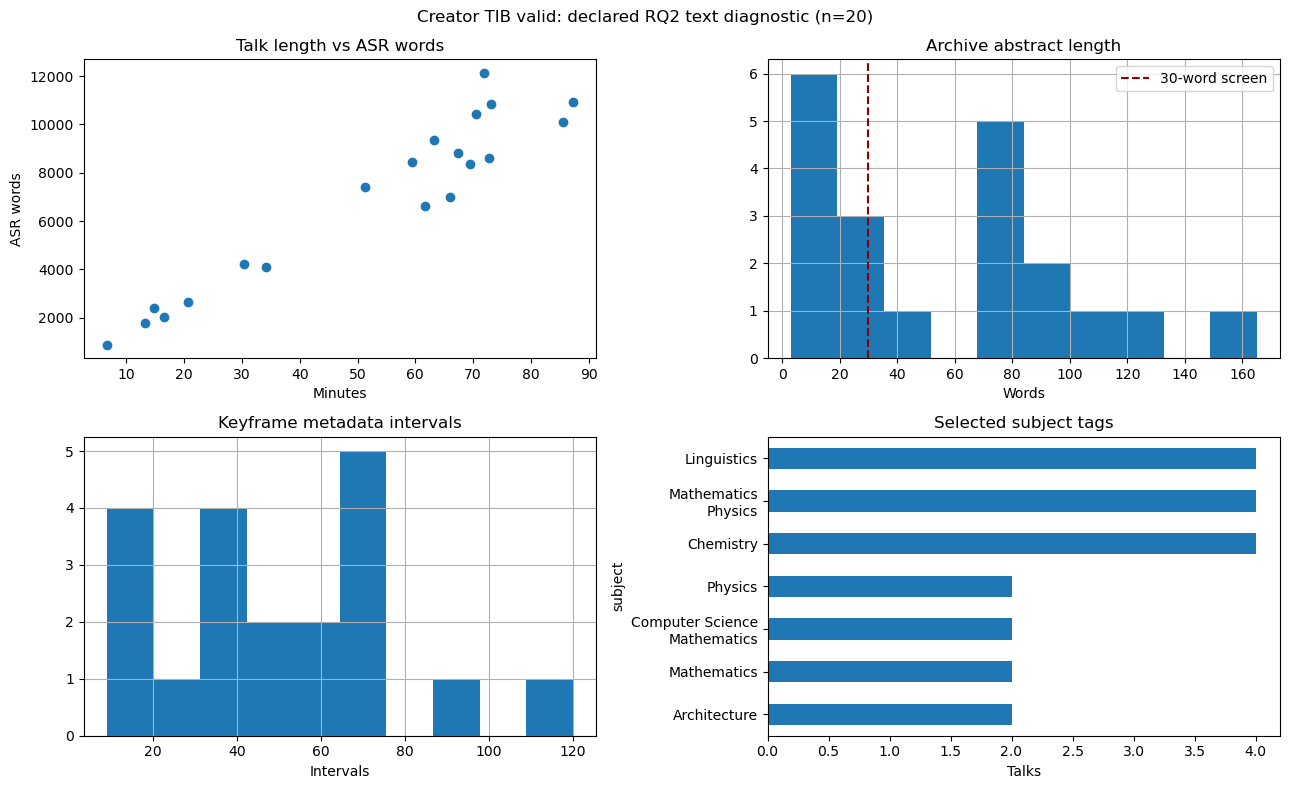

Exact-author train overlap: 13 / 20
Potential same-series train titles (manual audit): 9/20; formal group safety unproven
tib-bench train DOI intersection (DOI-only scan of 822 rows): 0/20


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0,0].scatter(detail_df.duration_minutes, detail_df.transcript_words)
axes[0,0].set(title="Talk length vs ASR words", xlabel="Minutes", ylabel="ASR words")
detail_df.abstract_words.hist(ax=axes[0,1], bins=10)
axes[0,1].axvline(30, color="darkred", linestyle="--", label="30-word screen")
axes[0,1].legend(); axes[0,1].set(title="Archive abstract length", xlabel="Words")
detail_df.keyframe_count.hist(ax=axes[1,0], bins=10)
axes[1,0].set(title="Keyframe metadata intervals", xlabel="Intervals")
detail_df.subject.value_counts().sort_values().plot.barh(ax=axes[1,1])
axes[1,1].set(title="Selected subject tags", xlabel="Talks")
fig.suptitle("Creator TIB valid: declared RQ2 text diagnostic (n=20)")
fig.tight_layout(); plt.show()
print("Exact-author train overlap:", int((detail_df.train_author_rows > 0).sum()), "/", len(detail_df))
print("Potential same-series train titles (manual audit): 9/20; formal group safety unproven")
print("tib-bench train DOI intersection (DOI-only scan of 822 rows): 0/20")

In [11]:
manifest_path = Path("experiments/outputs/diagnostic/rq2_valid_paired/manifest.json")
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if manifest.get("selection_sha256") == receipt["selected_doi_sha256"] and manifest.get("status") == "development_diagnostic_only":
        outputs = [json.loads(Path(row["path"]).read_text(encoding="utf-8")) for row in manifest["completed"]]
        print("S1/S3 diagnostic pairs:", len(outputs), "; failed:", len(manifest["failed"]))
        print("Prefix-truncated talks:", sum(row["input"]["prefix_truncated"] for row in outputs))
        print("Pairs exceeding 8k estimated cumulative prompt tokens:", sum(row["cumulative_prompt_budget_status"] == "estimate_exceeded" for row in outputs))
        print("Equal estimated cumulative prompt tokens:", sum(row["arms"]["S1"]["cumulative_prompt_token_estimate"] == row["arms"]["S3_lexical_cohesion"]["cumulative_prompt_token_estimate"] for row in outputs))
        print("Quality evaluation: not_run; this is NOT formal H2 evidence")
    else:
        print("S1/S3 artifact does not match selected cohort or is incomplete; not_run here")
else:
    print("S1/S3 diagnostic not_run")

S1/S3 diagnostic pairs: 20 ; failed: 0
Prefix-truncated talks: 13
Pairs exceeding 8k estimated cumulative prompt tokens: 13
Equal estimated cumulative prompt tokens: 0
Quality evaluation: not_run; this is NOT formal H2 evidence


## EDA decision — LIMIT

**Keep** the 20 pinned `valid` items for a **text-only development diagnostic** of S1/S3 pipeline behavior. The corpus is heterogeneous in duration (6.6–87.3 min), subjects, abstract style (3–165 words) and keyframe count. The transcript is source-linked automatic ASR; its word/timestamp consistency is visible above, but speech accuracy is unmeasured. The selected items do not form a verified group-safe formal holdout. Formal reference-based ROUGE/BERTScore has **0/20 qualified** references at this stage. S4 is `not_run`: the present keyframe metadata has no pixels/OCR and `tib-bench` has no DOI overlap.

**Decision boundary:** This notebook supports a decision to continue text-only diagnostic work. It does **not** authorize opening sealed final-test content, making a whole-talk summary-quality claim, or claiming an audio+visual RQ2 result. Before formal H2, qualify source speech/transcript, group-safe cohort, source-supported human rubric and measured equal-token generation. See [per-record audit](../../../../plans/reports/rq2-valid-dataset-audit-261002-report.md) and [RQ2 plan](../../../plans/261002-0946-rq2-controlled-summarization/plan.md).

**Unresolved questions:** What is transcript error against source audio? Which candidate abstract claims are supported and who supplied each abstract? Which source videos can provide permitted, aligned slide pixels/OCR for S4? What does the timed blinded human pilot imply for formal sample size?

## Export all structurally eligible Lecture metadata

This new cell uses the already loaded `rows` from the first EDA cell. It saves metadata for all structurally eligible `valid` Lecture talks so subject/length coverage can be compared with the selected 20. No test data or media bytes are read. Run this cell in the existing kernel; after a kernel restart, run the notebook from the beginning.

In [12]:
eligible = [r for r in rows if r["genre"].casefold() == "lecture" and r["doi"] and r["source_url_present"] and r["transcript_words"] > 0 and r["segment_count"] >= 2 and r["segments_valid_times"] and r["segments_ordered"]]
assert len(eligible) == receipt["candidate_count"]
fields = ["source_index", "doi", "title", "subject", "author", "genre", "transcript_words", "abstract_words", "duration_minutes", "segment_count", "language"]
metadata = {"dataset": receipt["dataset"], "revision": receipt["revision"], "split": "valid", "test_content_accessed": False, "selection_sha256": receipt["selected_doi_sha256"], "eligible_count": len(eligible), "records": [{key: row[key] for key in fields} for row in eligible]}
metadata_path = Path("plans/261002-0946-rq2-controlled-summarization/rq2-tib-valid-eligible-metadata.json")
metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Saved:", metadata_path, "| eligible:", len(eligible))
print(pd.DataFrame(eligible).subject.value_counts(dropna=False).to_string())

Saved: plans\261002-0946-rq2-controlled-summarization\rq2-tib-valid-eligible-metadata.json | eligible: 70
subject
Chemistry                        19
Physics                          15
Linguistics                      11
Mathematics\nPhysics             10
Mathematics                       7
Architecture                      3
Engineering                       3
Computer Science\nMathematics     2
